
# Surrogate studies — fixed thermal transport + margin-based controller

Fixes:
1. `lambda_brass(T)` is replaced by a stable, finite brass conductivity interpolation over 5–110 K.
2. Cryogenic heat capacity is replaced by log-log interpolated copper/stainless models.
3. The surrogate target is normalized margin `(Istar - I)/Istar`, not raw current margin.
4. Unsafe samples use a short post-runaway thermal rollout, not random temperature offsets.
5. The Fig. 7-style panel uses paper anchors only, not fake experimental scatter.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import brentq
from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

np.random.seed(7)


In [2]:

# ============================================================
# CONSTANTS
# ============================================================

U0 = 1e-7
Ic0 = 500.0
Tc = 85.0

L = 1.0
w = 0.004
d = 0.01

FIXED_N = 20.0
T_SAFE = 300.0

t_sc = 1.3e-6
t_cu = 50e-6
t_ss = 50e-6

A_sc = t_sc*w
A_cu = t_cu*w
A_ss = t_ss*w

rho_mass_cu = 8960.0
rho_mass_ss = 8000.0

RRR_CU = 24.0
rho_cu_300 = 1.6e-8
rho_ss_300 = 7.0e-7


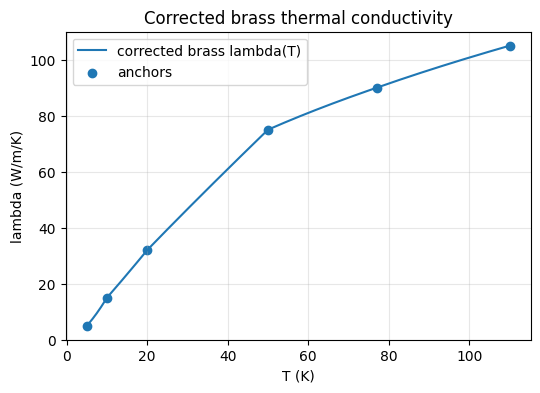

In [3]:

# ============================================================
# CORRECTED THERMAL CONDUCTIVITY FOR BRASS
# ============================================================
# Stable log-log interpolation through plausible 70Cu-30Zn brass values.
# This avoids the old underflow/collapse of lambda above ~25 K.

BRASS_T_ANCHOR = np.array([5.0, 10.0, 20.0, 50.0, 77.0, 110.0])
BRASS_K_ANCHOR = np.array([5.0, 15.0, 32.0, 75.0, 90.0, 105.0])

def lambda_brass(T):
    T = np.asarray(T)
    T_clip = np.clip(T, BRASS_T_ANCHOR[0], BRASS_T_ANCHOR[-1])
    logk = np.interp(
        np.log(T_clip),
        np.log(BRASS_T_ANCHOR),
        np.log(BRASS_K_ANCHOR)
    )
    return np.exp(logk)

Ts_check = np.linspace(5, 110, 300)
plt.figure(figsize=(6,4))
plt.plot(Ts_check, lambda_brass(Ts_check), label="corrected brass lambda(T)")
plt.scatter(BRASS_T_ANCHOR, BRASS_K_ANCHOR, label="anchors")
plt.xlabel("T (K)")
plt.ylabel("lambda (W/m/K)")
plt.title("Corrected brass thermal conductivity")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [5]:

# ============================================================
# TRANSPORT + COOLING MODELS
# ============================================================

def Ic(T):
    T = np.asarray(T)
    T_clip = np.clip(T, 1.0, Tc-1e-6)
    val = Ic0 * (1 - (T_clip/Tc)**1.7)
    return np.maximum(val, 1e-12)

def eta(T, lam_override=None):
    lam = lambda_brass(T) if lam_override is None else lam_override
    return lam * (2*w*L/d)

def Qout(T, T0, lam_override=None):
    T = np.asarray(T)
    T_clip = np.maximum(T, T0 + 1e-9)
    return eta(T_clip, lam_override=lam_override) * (T_clip - T0)

def rho_cu(T):
    T = np.asarray(T)
    rho0 = rho_cu_300/RRR_CU
    phonon = (rho_cu_300-rho0) * np.clip(T/300.0, 0, 1.5)**1.7
    return rho0 + phonon

def rho_ss(T):
    T = np.asarray(T)
    return rho_ss_300 * (0.85 + 0.15*np.clip(T/300.0, 0, 1.5))

def R_cu(T):
    return rho_cu(T)*L/A_cu

def R_ss(T):
    return rho_ss(T)*L/A_ss

def R_stabilizer(T):
    Rc = R_cu(T)
    Rs = R_ss(T)
    return 1.0/(1.0/Rc + 1.0/Rs)


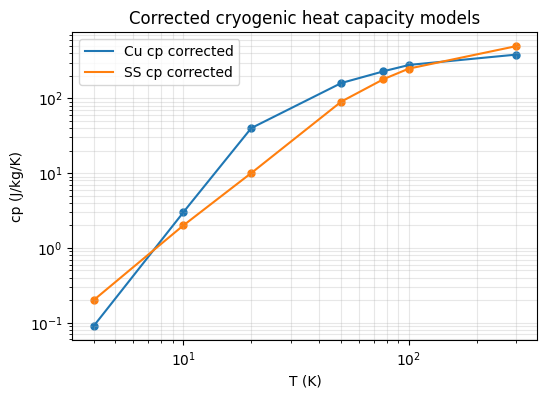

In [6]:

# ============================================================
# CORRECTED CRYOGENIC HEAT CAPACITY
# ============================================================

CU_T_CP = np.array([4.0, 10.0, 20.0, 50.0, 77.0, 100.0, 300.0])
CU_CP   = np.array([0.09, 3.0, 40.0, 160.0, 230.0, 280.0, 385.0])

SS_T_CP = np.array([4.0, 10.0, 20.0, 50.0, 77.0, 100.0, 300.0])
SS_CP   = np.array([0.20, 2.0, 10.0, 90.0, 180.0, 250.0, 500.0])

def _log_interp_cp(T, T_anchor, cp_anchor):
    T = np.asarray(T)
    T_clip = np.clip(T, T_anchor[0], T_anchor[-1])
    return np.exp(np.interp(np.log(T_clip), np.log(T_anchor), np.log(cp_anchor)))

def cp_cu(T):
    return _log_interp_cp(T, CU_T_CP, CU_CP)

def cp_ss(T):
    return _log_interp_cp(T, SS_T_CP, SS_CP)

def heat_capacity_per_m(T):
    T = np.asarray(T)
    C_cu = rho_mass_cu * A_cu * cp_cu(T)
    C_ss = rho_mass_ss * A_ss * cp_ss(T)
    return C_cu + C_ss + 0.15*(C_cu + C_ss)

Ts_check = np.linspace(4, 300, 500)
plt.figure(figsize=(6,4))
plt.loglog(Ts_check, cp_cu(Ts_check), label="Cu cp corrected")
plt.loglog(Ts_check, cp_ss(Ts_check), label="SS cp corrected")
plt.scatter(CU_T_CP, CU_CP, s=25)
plt.scatter(SS_T_CP, SS_CP, s=25)
plt.xlabel("T (K)")
plt.ylabel("cp (J/kg/K)")
plt.title("Corrected cryogenic heat capacity models")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()


In [7]:

# ============================================================
# STABILIZED CONDUCTOR CURRENT SHARING
# ============================================================

def solve_Ix(I, T, n):
    if I <= 0:
        return 0.0

    Rst = float(R_stabilizer(T))
    IcT = float(Ic(T))

    def f(ix):
        return U0*(ix/IcT)**n - (I-ix)*Rst

    try:
        return brentq(f, 0.0, I, maxiter=80)
    except ValueError:
        xs = np.linspace(0, I, 200)
        vals = np.abs([f(x) for x in xs])
        return xs[int(np.argmin(vals))]

def voltage_stab(I, T, n):
    Ix = solve_Ix(float(I), float(min(T, Tc-1e-6)), float(n))
    return U0 * (Ix/Ic(T))**n

def Qin_stab(I, T, n):
    return I * voltage_stab(I, T, n)

def equilibrium_current_stab_single_T(T, T0, n, lam_override=None):
    cooling = float(Qout(T, T0, lam_override=lam_override))

    def balance(I):
        return Qin_stab(I, T, n) - cooling

    lo = 0.0
    hi = max(2.0*float(Ic(T0)), 100.0)

    for _ in range(30):
        if balance(hi) > 0:
            break
        hi *= 1.5

    try:
        return brentq(balance, lo, hi, maxiter=100)
    except Exception:
        return np.nan

def solve_runaway_stab(T0, n, lam_override=None, n_branch=700):
    Ts = np.linspace(T0+1e-4, Tc-1e-4, n_branch)
    Is = np.array([
        equilibrium_current_stab_single_T(T, T0, n, lam_override=lam_override)
        for T in Ts
    ])
    Is = np.nan_to_num(Is, nan=0.0, posinf=0.0, neginf=0.0)

    dIdT = np.gradient(Is, Ts)
    candidates = np.where(np.diff(np.sign(dIdT)) < 0)[0]
    idx = candidates[0] if len(candidates) else int(np.argmax(Is))

    return float(Is[idx]), float(Ts[idx])


In [8]:

# ============================================================
# STABLE TEMPERATURE AND POST-RUNAWAY DYNAMICS
# ============================================================

def stable_surface_temperature_stab(I, T0, n, lam_override=None):
    def F(T):
        return Qin_stab(I, T, n) - Qout(T, T0, lam_override=lam_override)

    Ts = np.linspace(T0+1e-4, Tc-1e-4, 250)
    vals = np.array([F(T) for T in Ts])

    roots = []
    for k in range(len(Ts)-1):
        if vals[k] == 0 or vals[k]*vals[k+1] < 0:
            try:
                roots.append(brentq(F, Ts[k], Ts[k+1], maxiter=80))
            except Exception:
                pass

    if len(roots) == 0:
        return np.nan

    return min(roots)

def integrate_post_runaway_temperature(I, T_init, T0, n, t_final=0.06, dt=2e-4):
    T = float(T_init)
    steps = int(t_final/dt)

    for _ in range(steps):
        T_eval = min(T, T_SAFE)
        if T_eval < Tc:
            Pgen = Qin_stab(I, min(T_eval, Tc-1e-4), n)
            Pcool = Qout(min(T_eval, Tc-1e-4), T0)
        else:
            Pgen = I**2 * R_stabilizer(T_eval)
            Pcool = Qout(Tc-1e-4, T0)
        C = max(float(heat_capacity_per_m(T_eval)), 1e-12)
        T += dt*(Pgen-Pcool)/C
        if T >= T_SAFE:
            return T_SAFE

    return T

def dTdt_estimate(I, Tsurf, T0, n):
    Pgen = Qin_stab(I, min(Tsurf, Tc-1e-4), n)
    Pcool = Qout(min(Tsurf, Tc-1e-4), T0)
    C = max(float(heat_capacity_per_m(min(Tsurf, T_SAFE))), 1e-12)
    return (Pgen-Pcool)/C


In [18]:

# ============================================================
# TRAINING SET GENERATION
# ============================================================

def generate_observable_dataset(N=6000):
    rows = []

    for _ in range(N):
        if _%100 = 0:
            print(_)
        T0 = np.random.uniform(5, 80)
        n = np.random.uniform(10, 40)

        Istar, Tstar = solve_runaway_stab(T0, n)
        if not np.isfinite(Istar) or Istar <= 0:
            continue

        r = np.random.random()
        if r < 0.65:
            frac = np.random.uniform(0.82, 1.08)
        elif r < 0.85:
            frac = np.random.uniform(0.55, 0.82)
        else:
            frac = np.random.uniform(1.08, 1.25)

        I = frac * Istar

        if I < Istar:
            Tsurf = stable_surface_temperature_stab(I, T0, n)
            if not np.isfinite(Tsurf):
                continue
        else:
            Tsurf = integrate_post_runaway_temperature(I, Tstar, T0, n)

        V = voltage_stab(I, min(Tsurf, Tc-1e-4), n)
        Pgen = I*V
        Pcool = Qout(min(Tsurf, Tc-1e-4), T0)
        dTdt = dTdt_estimate(I, Tsurf, T0, n)
        margin_norm = (Istar - I)/Istar

        rows.append({
            "T0_K": T0,
            "n_value": n,
            "I_A": I,
            "T_surface_K": Tsurf,
            "deltaT_obs_K": Tsurf - T0,
            "voltage_V_per_m": V,
            "power_gen_W_per_m": Pgen,
            "power_cool_W_per_m": Pcool,
            "dTdt_est_K_per_s": dTdt,
            "Istar_A": Istar,
            "Tstar_K": Tstar,
            "deltaT_star_K": Tstar - T0,
            "normalized_margin": margin_norm,
            "current_margin_A": Istar - I,
            "runaway_label": int(margin_norm <= 0)
        })

    return pd.DataFrame(rows)

df = generate_observable_dataset(10000)
print(df.shape)
df.head()


SyntaxError: invalid syntax (303602460.py, line 9)

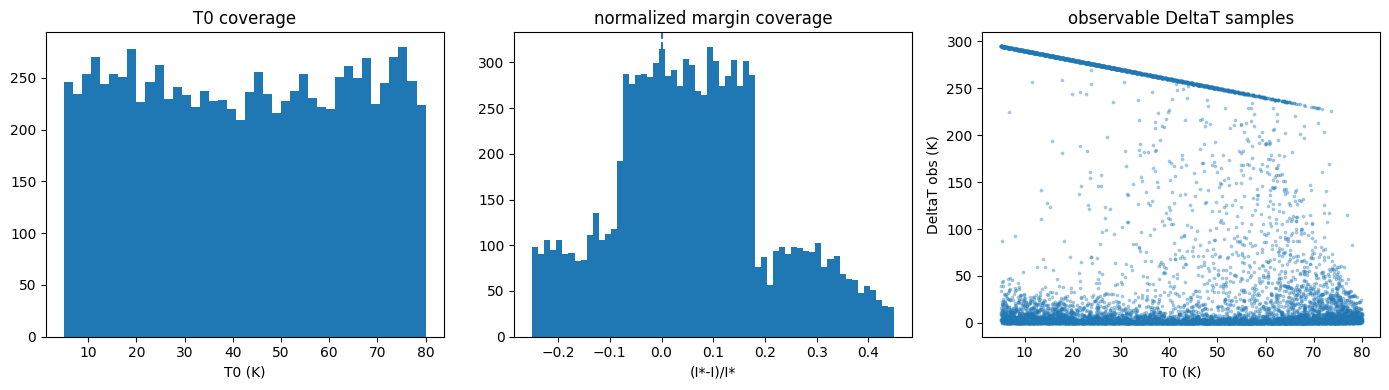

In [14]:

# ============================================================
# COVERAGE CHECK
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(14,4))

axes[0].hist(df["T0_K"], bins=40)
axes[0].set_title("T0 coverage")
axes[0].set_xlabel("T0 (K)")

axes[1].hist(df["normalized_margin"], bins=60)
axes[1].axvline(0, linestyle="--")
axes[1].set_title("normalized margin coverage")
axes[1].set_xlabel("(I*-I)/I*")

axes[2].scatter(df["T0_K"], df["deltaT_obs_K"], s=3, alpha=0.3)
axes[2].set_title("observable DeltaT samples")
axes[2].set_xlabel("T0 (K)")
axes[2].set_ylabel("DeltaT obs (K)")

plt.tight_layout()
plt.show()

df.to_csv("/home/maira/magnet_surr/thermal_runaway_observables_corrected.csv", index=False)


In [ ]:
# ============================================================
# TRAINING DATA VALIDATION BEFORE LEARNING
# ============================================================

print("Dataset rows:", len(df))
print("Columns:", list(df.columns))
df.head()

# ============================================================
# MATERIAL SANITY CHECKS
# ============================================================

Ts = np.linspace(5, 110, 400)

fig, axes = plt.subplots(1, 3, figsize=(16,4))

axes[0].plot(Ts, lambda_brass(Ts))
axes[0].scatter(BRASS_T_ANCHOR, BRASS_K_ANCHOR)
axes[0].set_title("Brass thermal conductivity")
axes[0].set_xlabel("T (K)")
axes[0].set_ylabel("lambda (W/m/K)")
axes[0].grid(True, alpha=0.3)

axes[1].loglog(Ts, cp_cu(Ts), label="Cu")
axes[1].loglog(Ts, cp_ss(Ts), label="SS")
axes[1].set_title("Cryogenic heat capacity")
axes[1].set_xlabel("T (K)")
axes[1].set_ylabel("cp (J/kg/K)")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

axes[2].plot(Ts, eta(Ts))
axes[2].set_title("Cooling coefficient eta(T)")
axes[2].set_xlabel("T (K)")
axes[2].set_ylabel("eta (W/K)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("lambda min/max:", lambda_brass(Ts).min(), lambda_brass(Ts).max())
print("eta min/max:", eta(Ts).min(), eta(Ts).max())

In [ ]:

# ============================================================
# MARGIN-BASED SURROGATE
# ============================================================

feature_cols = [
    "T0_K",
    "n_value",
    "I_A",
    "T_surface_K",
    "deltaT_obs_K",
    "voltage_V_per_m",
    "dTdt_est_K_per_s"
]

X = df[feature_cols].values
y = df["normalized_margin"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=11
)

margin_surrogate = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(
        max_iter=800,
        learning_rate=0.02,
        max_leaf_nodes=31,
        l2_regularization=0.03,
        random_state=11
    )
)

margin_surrogate.fit(X_train, y_train)
pred = margin_surrogate.predict(X_test)

print("Normalized margin surrogate")
print("MAE:", mean_absolute_error(y_test, pred))
print("R2:", r2_score(y_test, pred))

plt.figure(figsize=(5,5))
plt.scatter(y_test, pred, s=5, alpha=0.35)
plt.axline((0,0), slope=1, linestyle="--")
plt.axvline(0, linestyle=":")
plt.axhline(0, linestyle=":")
plt.xlabel("true normalized margin")
plt.ylabel("predicted normalized margin")
plt.title("Margin surrogate validation")
plt.grid(True, alpha=0.3)
plt.show()

def margin_to_risk(margin, tau=0.06):
    return expit(-margin/tau)

def estimate_runaway_risk_margin_based(T0_K, n_value, I_A, T_surface_K, voltage_V_per_m=None, tau=0.06):
    if voltage_V_per_m is None:
        voltage_V_per_m = voltage_stab(I_A, min(T_surface_K, Tc-1e-4), n_value)

    dTdt = dTdt_estimate(I_A, T_surface_K, T0_K, n_value)

    x = np.array([[
        T0_K,
        n_value,
        I_A,
        T_surface_K,
        T_surface_K - T0_K,
        voltage_V_per_m,
        dTdt
    ]])

    margin = float(margin_surrogate.predict(x)[0])
    risk = float(margin_to_risk(margin, tau=tau))

    if risk > 0.8:
        action = "SHUTDOWN_OR_RAMP_DOWN"
    elif risk > 0.45:
        action = "HOLD_OR_SLOW_RAMP"
    else:
        action = "SAFE_TO_CONTINUE"

    return {
        "normalized_margin": margin,
        "runaway_probability": risk,
        "recommended_action": action
    }


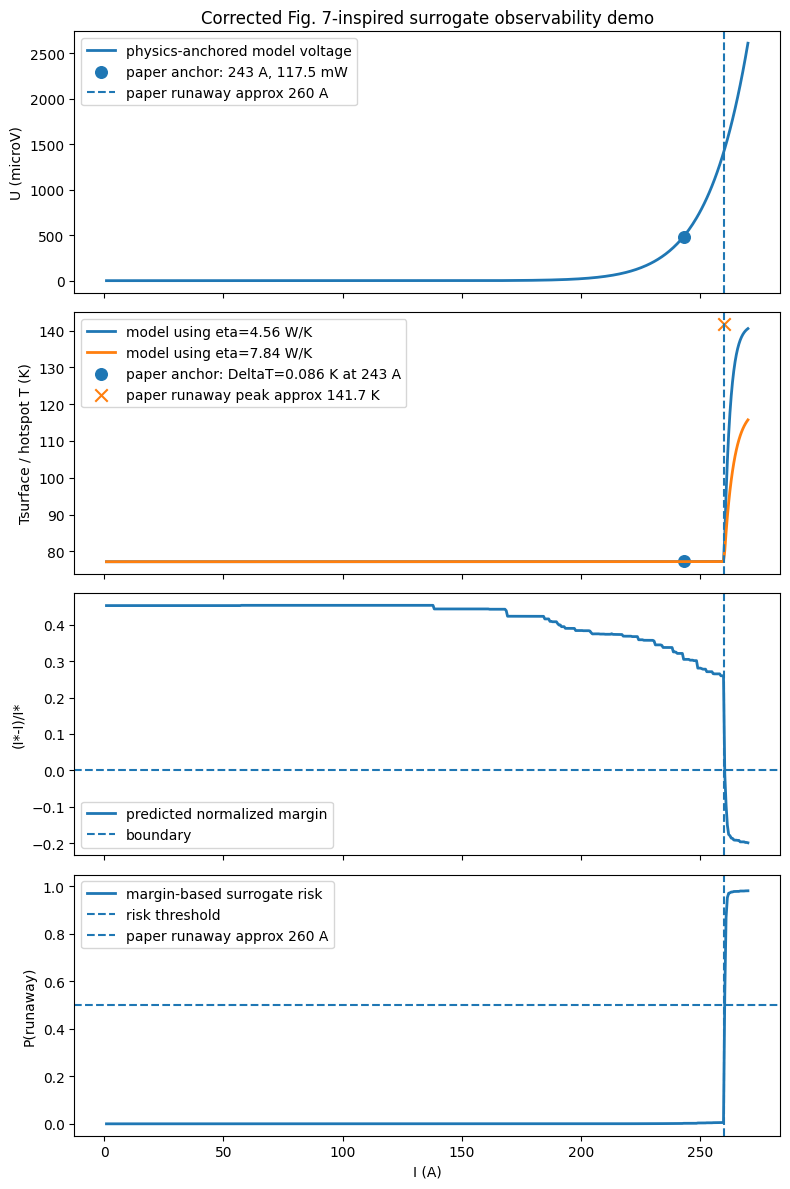

In [17]:

# ============================================================
# FIGURE 7-INSPIRED OBSERVABILITY DEMO WITH CORRECTED SURROGATE
# ============================================================
# Anchors only; no fake experimental scatter.

T0_exp = 77.2
I_stable_exp = 243.0
dT_stable_exp = 0.086
P_stable_exp = 117.5e-3
I_runaway_exp = 260.0
T_runaway_peak_exp = 141.7

eta_c_exp = 4.56
eta_h_exp = 7.84

n_eff = 16.0
U_at_stable_V = P_stable_exp/I_stable_exp

def voltage_fig7_physics(I, I_ref=I_stable_exp, U_ref=U_at_stable_V, n=n_eff):
    I = np.asarray(I)
    return U_ref*np.maximum(I/I_ref, 1e-12)**n

I_vals = np.linspace(1, 270, 500)
U_model_V = voltage_fig7_physics(I_vals)
U_model_uV = 1e6*U_model_V

P_model_W = I_vals*U_model_V
T_model_eta_c = T0_exp + P_model_W/eta_c_exp
T_model_eta_h = T0_exp + P_model_W/eta_h_exp

post_mask = I_vals >= I_runaway_exp
T_model_eta_c[post_mask] = (
    T0_exp + dT_stable_exp
    + (T_runaway_peak_exp - (T0_exp + dT_stable_exp))
    * (1 - np.exp(-(I_vals[post_mask]-I_runaway_exp)/2.5))
)
T_model_eta_h[post_mask] = (
    T0_exp + 0.5*dT_stable_exp
    + 0.65*(T_runaway_peak_exp - T0_exp)
    * (1 - np.exp(-(I_vals[post_mask]-I_runaway_exp)/4.0))
)

risk_vals = []
margin_vals = []

for I, Tsurf, Uv in zip(I_vals, T_model_eta_c, U_model_V):
    out = estimate_runaway_risk_margin_based(
        T0_K=T0_exp,
        n_value=n_eff,
        I_A=float(I),
        T_surface_K=float(Tsurf),
        voltage_V_per_m=float(Uv),
        tau=0.05
    )
    risk_vals.append(out["runaway_probability"])
    margin_vals.append(out["normalized_margin"])

risk_vals = np.asarray(risk_vals)
margin_vals = np.asarray(margin_vals)

fig, axes = plt.subplots(4, 1, figsize=(8, 12), sharex=True)

axes[0].plot(I_vals, U_model_uV, linewidth=2, label="physics-anchored model voltage")
axes[0].scatter([I_stable_exp], [1e6*U_at_stable_V], s=70, label="paper anchor: 243 A, 117.5 mW")
axes[0].axvline(I_runaway_exp, linestyle="--", label="paper runaway approx 260 A")
axes[0].set_ylabel("U (microV)")
axes[0].set_title("Corrected Fig. 7-inspired surrogate observability demo")
axes[0].legend()

axes[1].plot(I_vals, T_model_eta_c, linewidth=2, label="model using eta=4.56 W/K")
axes[1].plot(I_vals, T_model_eta_h, linewidth=2, label="model using eta=7.84 W/K")
axes[1].scatter([I_stable_exp], [T0_exp+dT_stable_exp], s=70, label="paper anchor: DeltaT=0.086 K at 243 A")
axes[1].scatter([I_runaway_exp], [T_runaway_peak_exp], s=80, marker="x", label="paper runaway peak approx 141.7 K")
axes[1].axvline(I_runaway_exp, linestyle="--")
axes[1].set_ylabel("Tsurface / hotspot T (K)")
axes[1].legend()

axes[2].plot(I_vals, margin_vals, linewidth=2, label="predicted normalized margin")
axes[2].axhline(0, linestyle="--", label="boundary")
axes[2].axvline(I_runaway_exp, linestyle="--")
axes[2].set_ylabel("(I*-I)/I*")
axes[2].legend()

axes[3].plot(I_vals, risk_vals, linewidth=2, label="margin-based surrogate risk")
axes[3].axhline(0.5, linestyle="--", label="risk threshold")
axes[3].axvline(I_runaway_exp, linestyle="--", label="paper runaway approx 260 A")
axes[3].set_xlabel("I (A)")
axes[3].set_ylabel("P(runaway)")
axes[3].set_ylim(-0.05, 1.05)
axes[3].legend()

plt.tight_layout()
plt.show()



## Notes

This corrected notebook should no longer learn a degenerate \(I_c(T_0)\) threshold over most of the training set.

Key changes:

- Brass conductivity is finite and physical from 5–110 K.
- Heat capacity is plausible at cryogenic temperatures.
- The surrogate learns normalized margin, not raw current margin.
- Unsafe samples use a short dynamic rollout instead of random post-boundary temperatures.
- The Fig. 7-style panel uses paper anchors only; it does not present synthetic points as experimental data.

For true experimental validation, the next step is to digitize the actual Fig. 7 curves or use raw data from the authors and evaluate the trained surrogate directly on those measurements.


In [ ]:
# GRU based model history dependent 